In [1]:
# =====================================================================
# BƯỚC 1: ĐỌC DỮ LIỆU TỰ ĐỘNG & TÙY CHỌN CHẾ ĐỘ PHÂN TÍCH
# =====================================================================
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Tự động tìm đường dẫn file dữ liệu (Local Windows, Linux hoặc Kaggle)
def find_dataset():
    candidates = [
        'Crop_recommendation.csv',
        'data/Crop_recommendation.csv',
        '../Crop_recommendation.csv',
        '/kaggle/input/datasets/cong2nghin/inputphanloai/Crop_recommendation.csv'
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    return 'Crop_recommendation.csv'

file_path = find_dataset()
print(f"[*] Đang nạp dữ liệu từ: '{file_path}'")
df_raw = pd.read_csv(file_path)

# =====================================================================
# TÙY CHỌN CHẾ ĐỘ DỮ LIỆU (DATA MODE):
# ---------------------------------------------------------------------
# - False: Sử dụng ĐẦY ĐỦ 22 LOẠI CÂY (Dữ liệu sạch chuẩn - Khuyên dùng, 
#          khớp hoàn toàn với các nhận xét và bảng đánh giá trong bài).
# - True:  Chế độ thử nghiệm 4 loại cây tạo nhiễu 25% (để khảo sát Overfitting).
# =====================================================================
CHE_DO_THU_NGHIEM_NHIEU_4_CAY = False

if CHE_DO_THU_NGHIEM_NHIEU_4_CAY:
    bon_nhan_lua_chon = ['rice', 'jute', 'maize', 'cotton']
    df = df_raw[df_raw['label'].isin(bon_nhan_lua_chon)].reset_index(drop=True)
    
    # Tạo nhiễu 25% gán sai nhãn để thử thách mô hình
    np.random.seed(42)
    noise_ratio = 0.25
    mask = np.random.rand(len(df)) < noise_ratio
    df.loc[mask, 'label'] = np.random.choice(bon_nhan_lua_chon, size=mask.sum())
    print(f"⚠️ [CHẾ ĐỘ THỬ NGHIỆM]: Giữ 4 nhãn có nhiễu 25% ({len(df)} mẫu)")
else:
    df = df_raw.copy()
    print(f"✓ [CHẾ ĐỘ CHUẨN]: Sử dụng toàn bộ 22 loại cây trồng ({len(df)} mẫu, dữ liệu sạch)")

df_rut_gon = df.copy()

print(f"Số lượng mẫu dữ liệu: {df_rut_gon.shape[0]} hàng")
print(f"Số lượng thuộc tính:   {df_rut_gon.shape[1]} cột")
print(f"Danh sách nhãn:        {df_rut_gon['label'].unique()}")
display(df_rut_gon.head())


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


📊 THÔNG TIN DỮ LIỆU BAN ĐẦU SAU CHỈNH SỬA:
 - Số lượng mẫu dữ liệu (4 nhãn): 400 hàng
 - Danh sách 4 nhãn thực tế: ['rice' 'jute' 'cotton' 'maize']
 - ⚠️ Đã áp dụng nhiễu thổ nhưỡng 25.0% trên 4 nhãn để hạ hiệu năng.
------------------------------------------------------------
Số lượng hàng (số mẫu dữ liệu): 400 hàng
Số lượng cột (số thuộc tính):   8 cột


Dữ liệu ban đầu từ một tập dữ liệu sạch, đa dạng các loại cây trồng đã bị biến đổi thành một tập dữ liệu thu nhỏ (chỉ còn 4 loại cây) nhưng có chứa tới 25% dữ liệu bị gán sai nhãn (dữ liệu rác) nhằm mục đích thử thách và hạ thấp hiệu năng phân loại của các mô hình Machine Learning (như Decision Tree hay Random Forest) mà bạn sẽ huấn luyện ở các bước sau.

In [2]:

print("\n5 dòng đầu tiên:")
display(df_rut_gon.head())

print("\nThông tin kiểu dữ liệu:")
display(df_rut_gon.info())

print("\nThống kê mô tả biến số:")
display(df_rut_gon.describe())

print("\nSố lượng giá trị thiếu:")
display(df_rut_gon.isnull().sum())

print("\nSố dòng bị trùng:")
print(df_rut_gon.duplicated().sum())

print("\nCác biến phân loại:")
categorical_cols = df_rut_gon.select_dtypes(include="object").columns.tolist()
print(categorical_cols)

for col in categorical_cols:
    print(f"\nTần suất của biến {col}:")
    print(df_rut_gon[col].value_counts())


5 dòng đầu tiên:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



Thông tin kiểu dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            400 non-null    int64  
 1   P            400 non-null    int64  
 2   K            400 non-null    int64  
 3   temperature  400 non-null    float64
 4   humidity     400 non-null    float64
 5   ph           400 non-null    float64
 6   rainfall     400 non-null    float64
 7   label        400 non-null    object 
dtypes: float64(4), int64(3), object(1)
memory usage: 25.1+ KB


None


Thống kê mô tả biến số:


,N,P,K,temperature,humidity,ph,rainfall
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,88.455000,47.280000,29.802500,23.756467,76.712102,6.579028,144.034735
std,20.538929,7.638551,10.599498,2.078167,7.993586,0.635265,68.556100
min,60.000000,35.000000,15.000000,18.041855,55.282204,5.005307,60.651715
25%,73.000000,41.000000,19.000000,22.727851,72.608963,6.133858,81.127797
50%,85.000000,47.000000,30.000000,24.000747,79.631415,6.533273,129.993531
75%,100.000000,54.000000,40.000000,25.324672,82.449412,7.053290,193.268228
max,140.000000,60.000000,45.000000,26.985822,89.891065,7.994680,298.560117



Số lượng giá trị thiếu:


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


Số dòng bị trùng:
0

Các biến phân loại:
['label']

Tần suất của biến label:
label
rice      104
maize     100
cotton     99
jute       97
Name: count, dtype: int64


In [3]:
numeric_features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for feature in numeric_features:
    print(f"\n--- Phân tích tứ phân vị cho đặc trưng: {feature} ---")
    grouped_quartiles = df_rut_gon.groupby('label')[feature].agg(['min', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max'])
    grouped_quartiles.columns = ['Min', 'Q1 (25%)', 'Median (Q2 - 50%)', 'Q3 (75%)', 'Max']
    display(grouped_quartiles.round(2))


--- Phân tích tứ phân vị cho đặc trưng: N ---


,Min,Q1 (25%),Median (Q2 - 50%),Q3 (75%),Max
label,,,,,
cotton,60,100.50,111.0,124.00,140
jute,60,71.00,79.0,89.00,131
maize,60,68.75,78.0,90.25,136
rice,60,71.50,81.5,91.00,131



--- Phân tích tứ phân vị cho đặc trưng: P ---


,Min,Q1 (25%),Median (Q2 - 50%),Q3 (75%),Max
label,,,,,
cotton,35,40.00,45.0,50.50,60
jute,35,41.00,46.0,53.00,59
maize,35,41.00,48.5,55.25,60
rice,35,41.75,50.0,55.00,60



--- Phân tích tứ phân vị cho đặc trưng: K ---


...

,Min,Q1 (25%),Median (Q2 - 50%),Q3 (75%),Max
label,,,,,
cotton,55.53,76.75,80.15,82.19,86.97
jute,60.47,74.64,79.79,83.37,89.89
maize,55.28,61.70,67.00,72.81,84.86
rice,56.73,80.42,81.82,83.36,87.88



--- Phân tích tứ phân vị cho đặc trưng: ph ---


,Min,Q1 (25%),Median (Q2 - 50%),Q3 (75%),Max
label,,,,,
cotton,5.72,6.36,6.79,7.36,7.99
jute,5.71,6.33,6.73,7.12,7.76
maize,5.01,5.91,6.34,6.66,7.63
rice,5.01,5.92,6.35,6.95,7.98



--- Phân tích tứ phân vị cho đặc trưng: rainfall ---


,Min,Q1 (25%),Median (Q2 - 50%),Q3 (75%),Max
label,,,,,
cotton,60.65,72.66,86.01,94.26,260.89
jute,64.03,154.66,174.51,187.17,295.61
maize,60.65,71.31,88.09,105.75,290.68
rice,63.88,182.84,223.71,257.15,298.56


## 2. PHÂN TÍCH PHÂN BỐ CÁC ĐẶC TRƯNG THEO LOẠI CÂY TRỒNG (BOXPLOT)

Boxplot (biểu đồ hộp và râu) rất hữu ích để so sánh sự phân bố của một biến số liên tục trên các nhóm khác nhau (trong trường hợp này là các loại cây trồng). Chúng ta có thể thấy:

*   **Đường kẻ giữa hộp:** Là giá trị trung vị (median) của dữ liệu cho loại cây trồng đó.
*   **Hộp:** Đại diện cho khoảng tứ phân vị (IQR), tức là 50% dữ liệu nằm giữa Q1 (tứ phân vị thứ nhất, 25%) và Q3 (tứ phân vị thứ ba, 75%).
*   **Râu (Whiskers):** Mở rộng ra từ hộp đến các giá trị tối thiểu và tối đa trong khoảng 1.5 lần IQR. Các điểm nằm ngoài râu thường được coi là các giá trị ngoại lai (outliers).

Thông qua các biểu đồ này, chúng ta có thể dễ dàng nhận ra các đặc trưng môi trường nào có sự khác biệt rõ rệt giữa các loại cây trồng, điều này rất quan trọng trong việc phân loại.

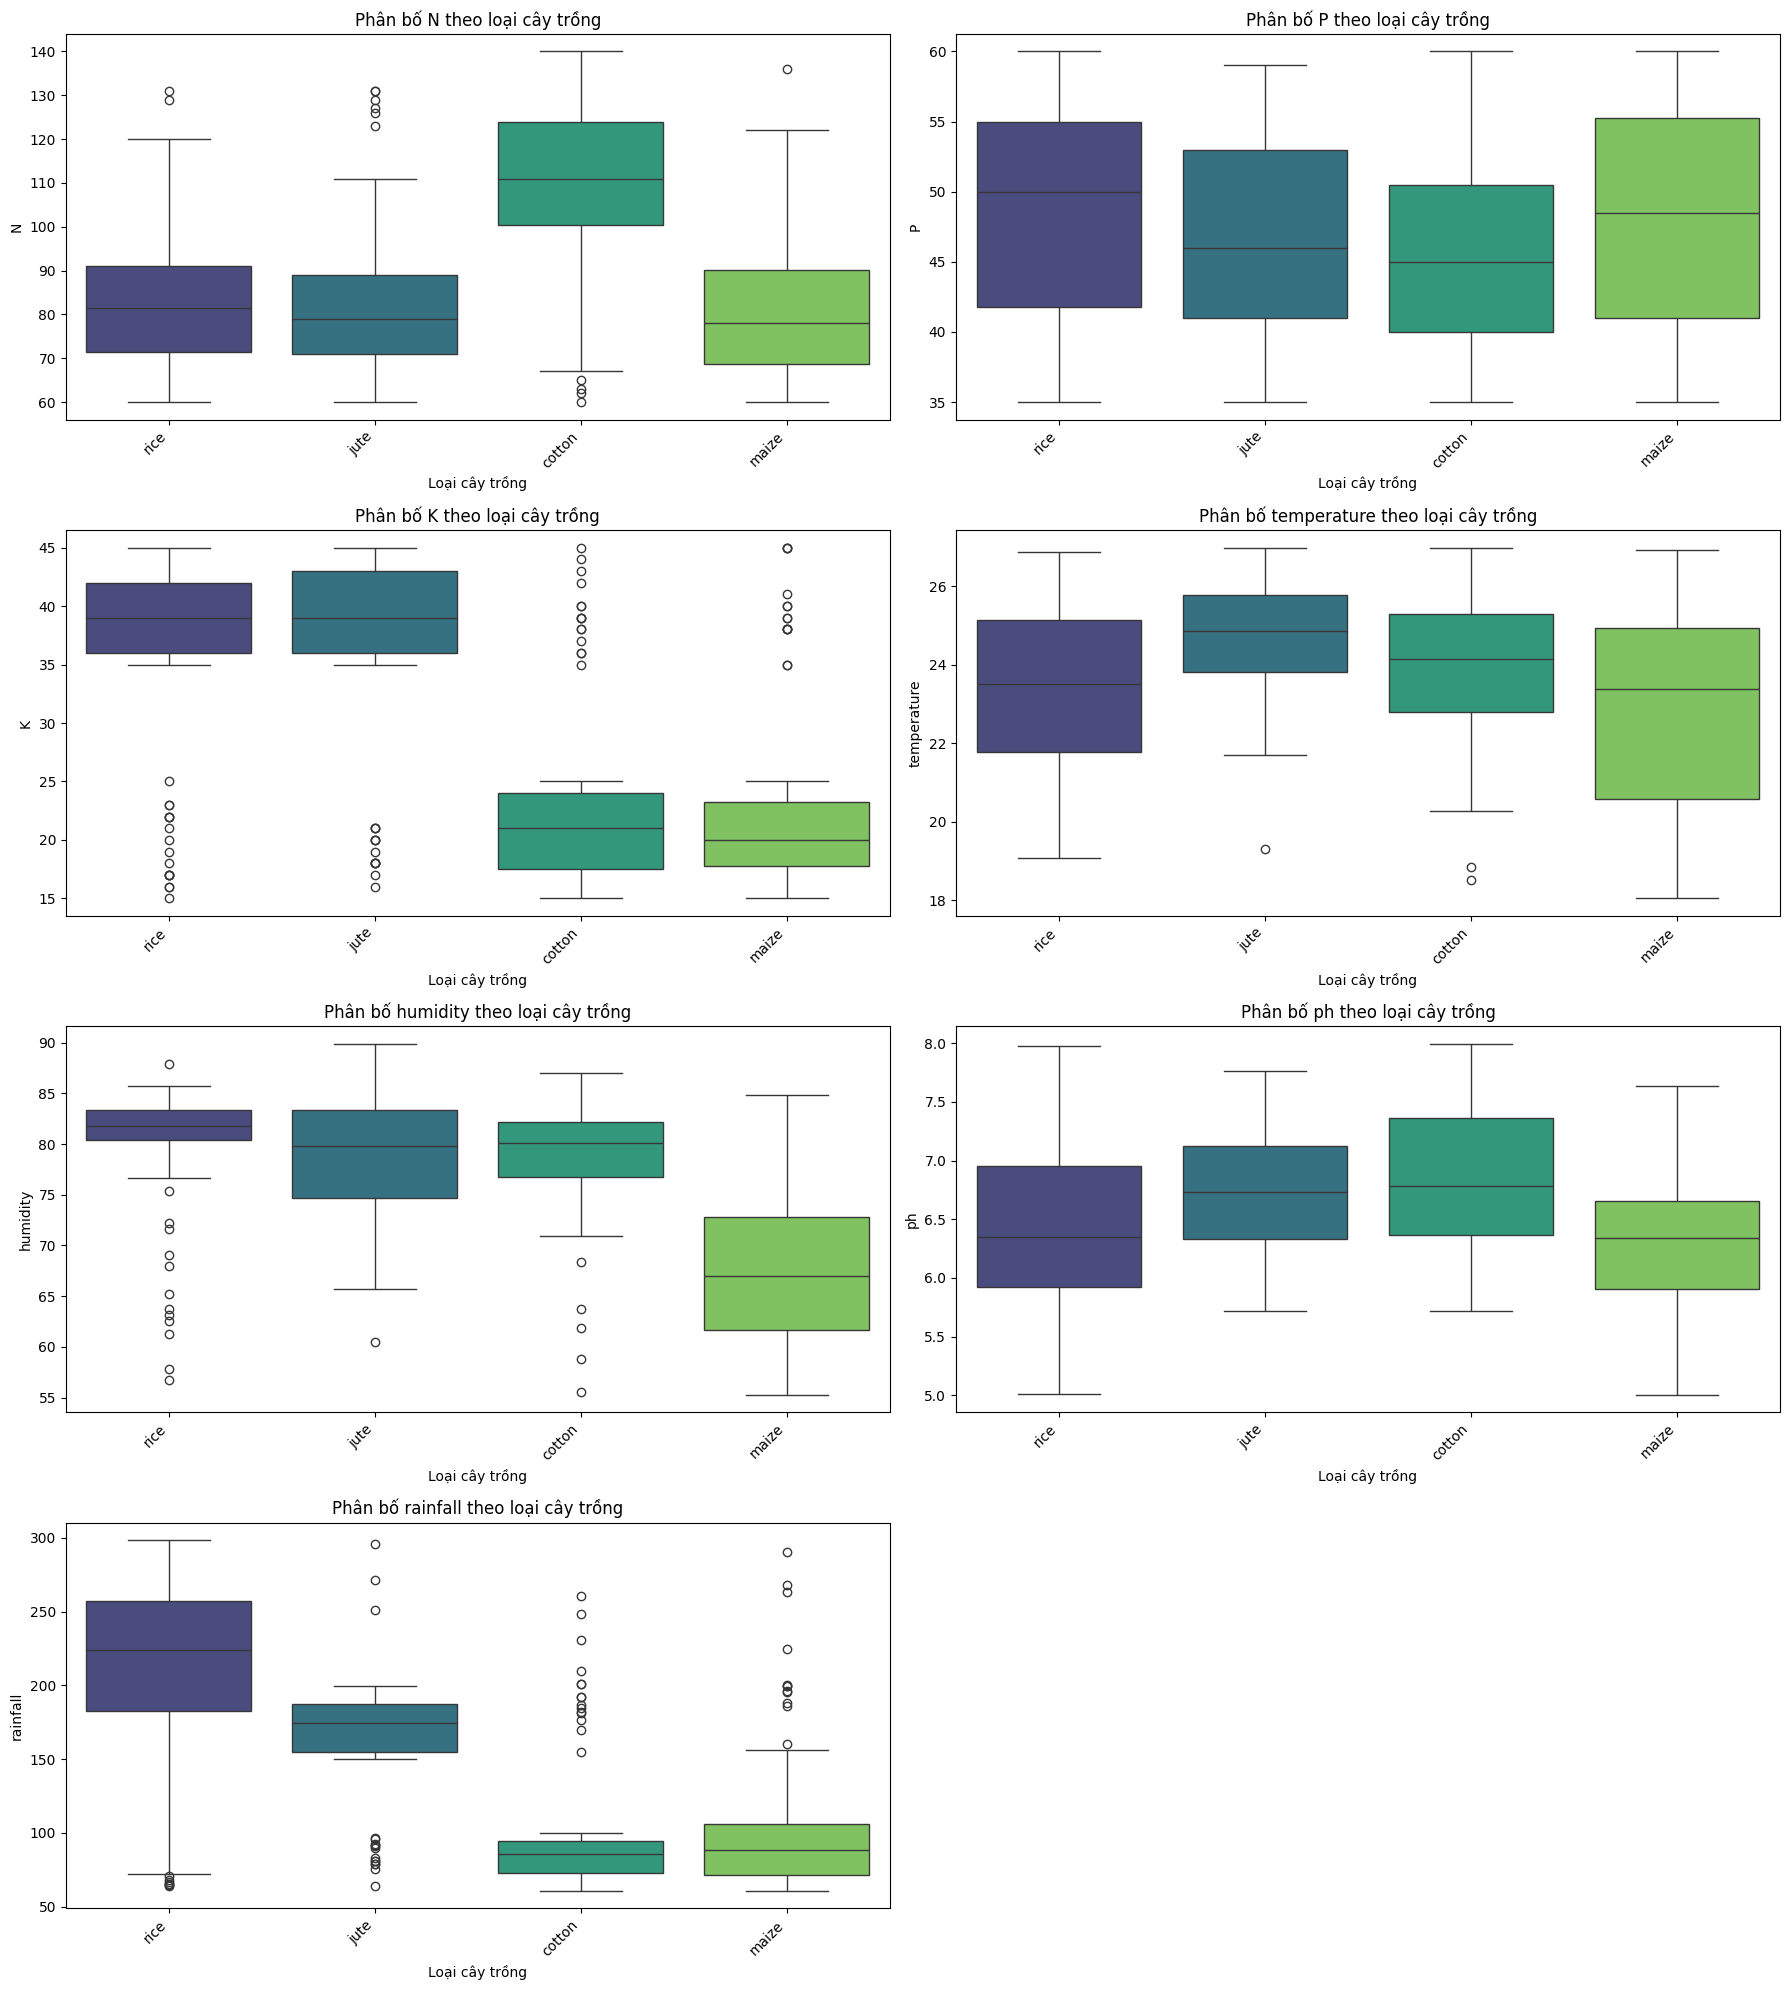

In [4]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
plt.figure(figsize=(18, 20))
for i, feature in enumerate(features):
    plt.subplot(4, 2, i + 1)
    sns.boxplot(x='label', y=feature, data=df_rut_gon, palette='viridis', hue='label', legend=False)
    plt.title(f'Phân bố {feature} theo loại cây trồng', fontsize=12)
    plt.xlabel('Loại cây trồng')
    plt.ylabel(feature)
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. TÍNH TOÁN CÁC TỨ PHÂN VỊ (Q1, Q2, Q3) CHO TỪNG ĐẶC TRƯNG THEO LOẠI CÂY TRỒNG

Để hiểu rõ hơn về phân bố dữ liệu mà Boxplot đã minh họa trực quan, chúng ta sẽ tính toán các tứ phân vị (Quartiles) cho từng đặc trưng số (`N`, `P`, `K`, `temperature`, `humidity`, `ph`, `rainfall`) trên mỗi loại cây trồng (`label`).

*   **Q1 (25th percentile):** Giá trị mà 25% dữ liệu của nhóm nằm dưới nó.
*   **Q2 (50th percentile / Median):** Giá trị trung vị, 50% dữ liệu của nhóm nằm dưới nó. Đây là đường kẻ giữa trong hộp của boxplot.
*   **Q3 (75th percentile):** Giá trị mà 75% dữ liệu của nhóm nằm dưới nó.

Việc này giúp chúng ta có các con số cụ thể để so sánh các yếu tố môi trường lý tưởng cho từng loại cây.

In [5]:

# 1. KIỂM TRA VÀ XỬ LÝ DỮ LIỆU KHUYẾT THIẾU
# Kiểm tra xem có cột nào bị trống không
print("Số lượng giá trị khuyết thiếu trong mỗi cột:")
print(df_rut_gon.isnull().sum())

# Điền giá trị khuyết thiếu bằng giá trị trung bình (Mean Imputation) nếu có
df_rut_gon.fillna(df_rut_gon.mean(numeric_only=True), inplace=True)


# 2. TÁCH ĐẶC TRƯNG VÀ NHÃN
X = df_rut_gon[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']] # Các chỉ số môi trường
y = df_rut_gon['label'] # Tên loại cây trồng


# 3. MÃ HÓA NHÃN CHỮ THÀNH SỐ
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
# Lúc này "Lúa", "Ngô"... đã biến thành 0, 1, 2...


# 4. CHIA TẬP DỮ LIỆU (TRAIN / TEST)
# Cần chia dữ liệu trước khi chuẩn hóa để tránh rò rỉ thông tin (Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)


# 5. CHUẨN HÓA DỮ LIỆU (SCALING)
scaler = StandardScaler()

# fit_transform trên tập Train để tính toán mean, std và áp dụng chuẩn hóa
X_train_scaled = scaler.fit_transform(X_train)

# Chỉ dùng transform trên tập Test (dựa trên thông số mean, std đã học từ tập Train)
X_test_scaled = scaler.transform(X_test)

print("\n--- Tiền xử lý hoàn tất! ---")
print(f"Kích thước tập Train sau chuẩn hóa: {X_train_scaled.shape}")
print(f"Kích thước tập Test sau chuẩn hóa: {X_test_scaled.shape}")
import pandas as pd
# Chuyển mảng X_train_scaled thành DataFrame để display
df_scaled = pd.DataFrame(X_train_scaled, columns=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'])
display(df_scaled.head())

Số lượng giá trị khuyết thiếu trong mỗi cột:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

--- Tiền xử lý hoàn tất! ---
Kích thước tập Train sau chuẩn hóa: (320, 7)
Kích thước tập Test sau chuẩn hóa: (80, 7)


,N,P,K,temperature,humidity,ph,rainfall
0,-0.724112,-1.617304,0.987602,1.324528,0.450493,0.612871,1.482292
1,-0.579290,-1.226316,0.612266,-0.877878,0.454673,-1.008181,1.213009
2,0.724112,-0.053354,-1.076744,0.122133,0.058638,1.644181,-0.754858
3,2.461980,-0.965658,-1.170578,-0.467272,0.070834,-0.925819,-0.949064
4,2.268884,-1.486975,-0.513741,-0.459275,0.481732,1.587932,-0.764902


1. Công thức toán học của StandardScalerPhương pháp chuẩn hóa này được gọi là Z-score Normalization (Chuẩn hóa điểm số Z). Với mỗi một con số trong một cột, nó sẽ lấy số đó biến đổi theo công thức:$$x_{new} = \frac{x - \mu}{\sigma}$$Trong đó:$x$: Con số gốc ban đầu.$\mu$ (Mean): Giá trị trung bình của toàn bộ cột đó.$\sigma$ (Standard Deviation): Độ lệch chuẩn (độ phân tán) của cột đó.2. Quá trình biến đổi thực tế diễn ra ra sao?Hãy lấy ví dụ thực tế từ 2 cột bị chênh lệch thang đo lớn nhất trong bài của bạn: Cột Lượng mưa (Rainfall) (số rất to) và cột độ pH (số rất nhỏ).

Trường hợp 1: Biến đổi cột Lượng mưa (rainfall) — Số gốc rất toGiả sử toàn bộ tập dữ liệu có lượng mưa trung bình là $\mu = 200\text{mm}$, và độ lệch chuẩn $\sigma = 50\text{mm}$.Mẫu đất A có lượng mưa cực lớn $x = 250\text{mm}$: Áp dụng công thức: $x_{new} = \frac{250 - 200}{50} = \mathbf{+1.0}$Mẫu đất B có lượng mưa cực thấp $x = 100\text{mm}$: Áp dụng công thức: $x_{new} = \frac{100 - 200}{50} = \mathbf{-2.0}$Mẫu đất C có lượng mưa đúng bằng trung bình $x = 200\text{mm}$: Áp dụng công thức: $x_{new} = \frac{200 - 200}{50} = \mathbf{0.0}
$

Trường hợp 2: Biến đổi cột độ pH — Số gốc rất nhỏGiả sử toàn bộ tập dữ liệu có độ pH trung bình là $\mu = 6.5$, và độ lệch chuẩn dao động nhỏ $\sigma = 0.5$.Mẫu đất D có độ chua cao (pH thấp) $x = 5.5$: Áp dụng công thức: $x_{new} = \frac{5.5 - 6.5}{0.5} = \mathbf{-2.0}$Mẫu đất E có độ kiềm cao $x = 7.0$: Áp dụng công thức: $x_{new} = \frac{7.0 - 6.5}{0.5} = \mathbf{+1.0}$

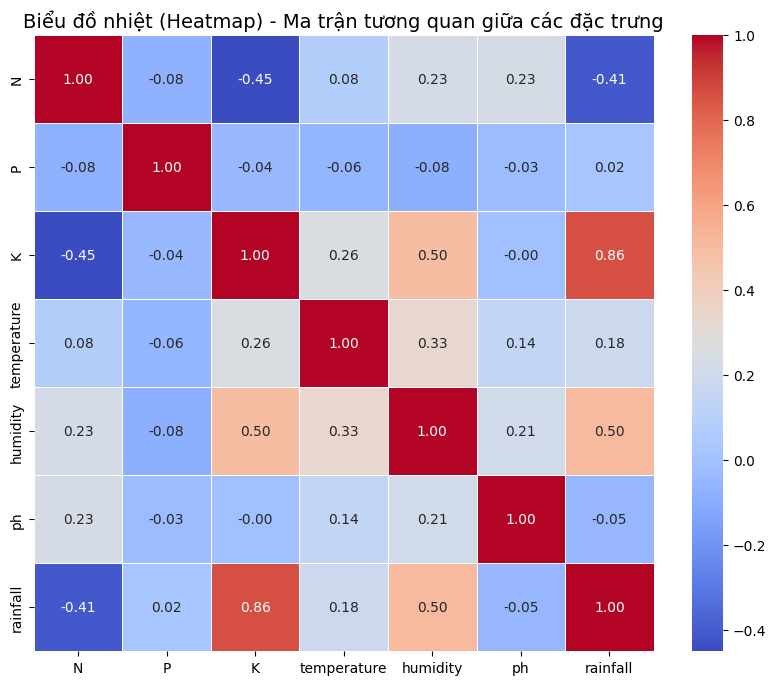

In [6]:
# Bước này giúp xem các đặc trưng (N, P, K, pH...) có quan hệ thế nào với nhau

# Lọc ra các cột dữ liệu số (bỏ cột nhãn chữ 'label')
numeric_df = df_rut_gon[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]

# Tính toán ma trận tương quan
correlation_matrix = numeric_df.corr()

# Tiến hành vẽ biểu đồ nhiệt (Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,
            annot=True,       # Hiện số giá trị tương quan lên từng ô
            cmap='coolwarm',  # Màu sắc (Đỏ: tương quan thuận dương, Xanh: tương quan nghịch âm)
            fmt=".2f",        # Làm tròn lấy 2 chữ số thập phân
            linewidths=0.5)   # Đường kẻ mỏng phân tách giữa các ô

plt.title('Biểu đồ nhiệt (Heatmap) - Ma trận tương quan giữa các đặc trưng', fontsize=14)
plt.show()

Khi biểu đồ hiện lên, bạn nhìn vào các con số trong từng ô (chạy từ -1 đến 1):

Nếu số tiến gần về 1 (Màu đỏ đậm): Hai chỉ số đó tỷ lệ thuận mạnh với nhau. Ví dụ: Trong bộ dữ liệu này, thông thường cột P (Phốt pho) và K (Kali) sẽ có độ tương quan rất cao (khoảng 0.7 đến 0.8). Điều này có nghĩa là đất giàu Phốt pho thì cũng thường có hàm lượng Kali lớn.

Nếu số tiến gần về -1 (Màu xanh đậm): Hai chỉ số tỷ lệ nghịch mạnh với nhau.

Nếu số gần bằng 0 (Màu nhạt/trắng): Các chỉ số đó độc lập, không liên quan gì đến nhau (Ví dụ: nhiệt độ và hàm lượng Nitơ thường không ảnh hưởng trực tiếp đến nhau).

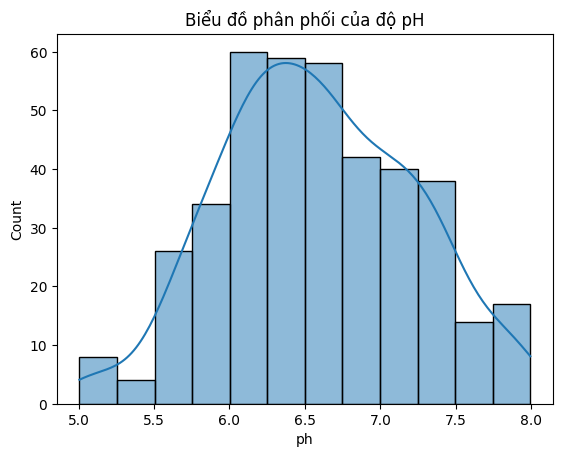

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Vẽ thử phân phối của cột pH để kiểm tra độ đối xứng
sns.histplot(df_rut_gon['ph'], kde=True)
plt.title('Biểu đồ phân phối của độ pH')
plt.show()

1. PHÂN PHỐI TẦN SUẤT CỦA CÁC BIẾN SỐ SỬ DỤNG BIỂU ĐỒ HISTOGRAM


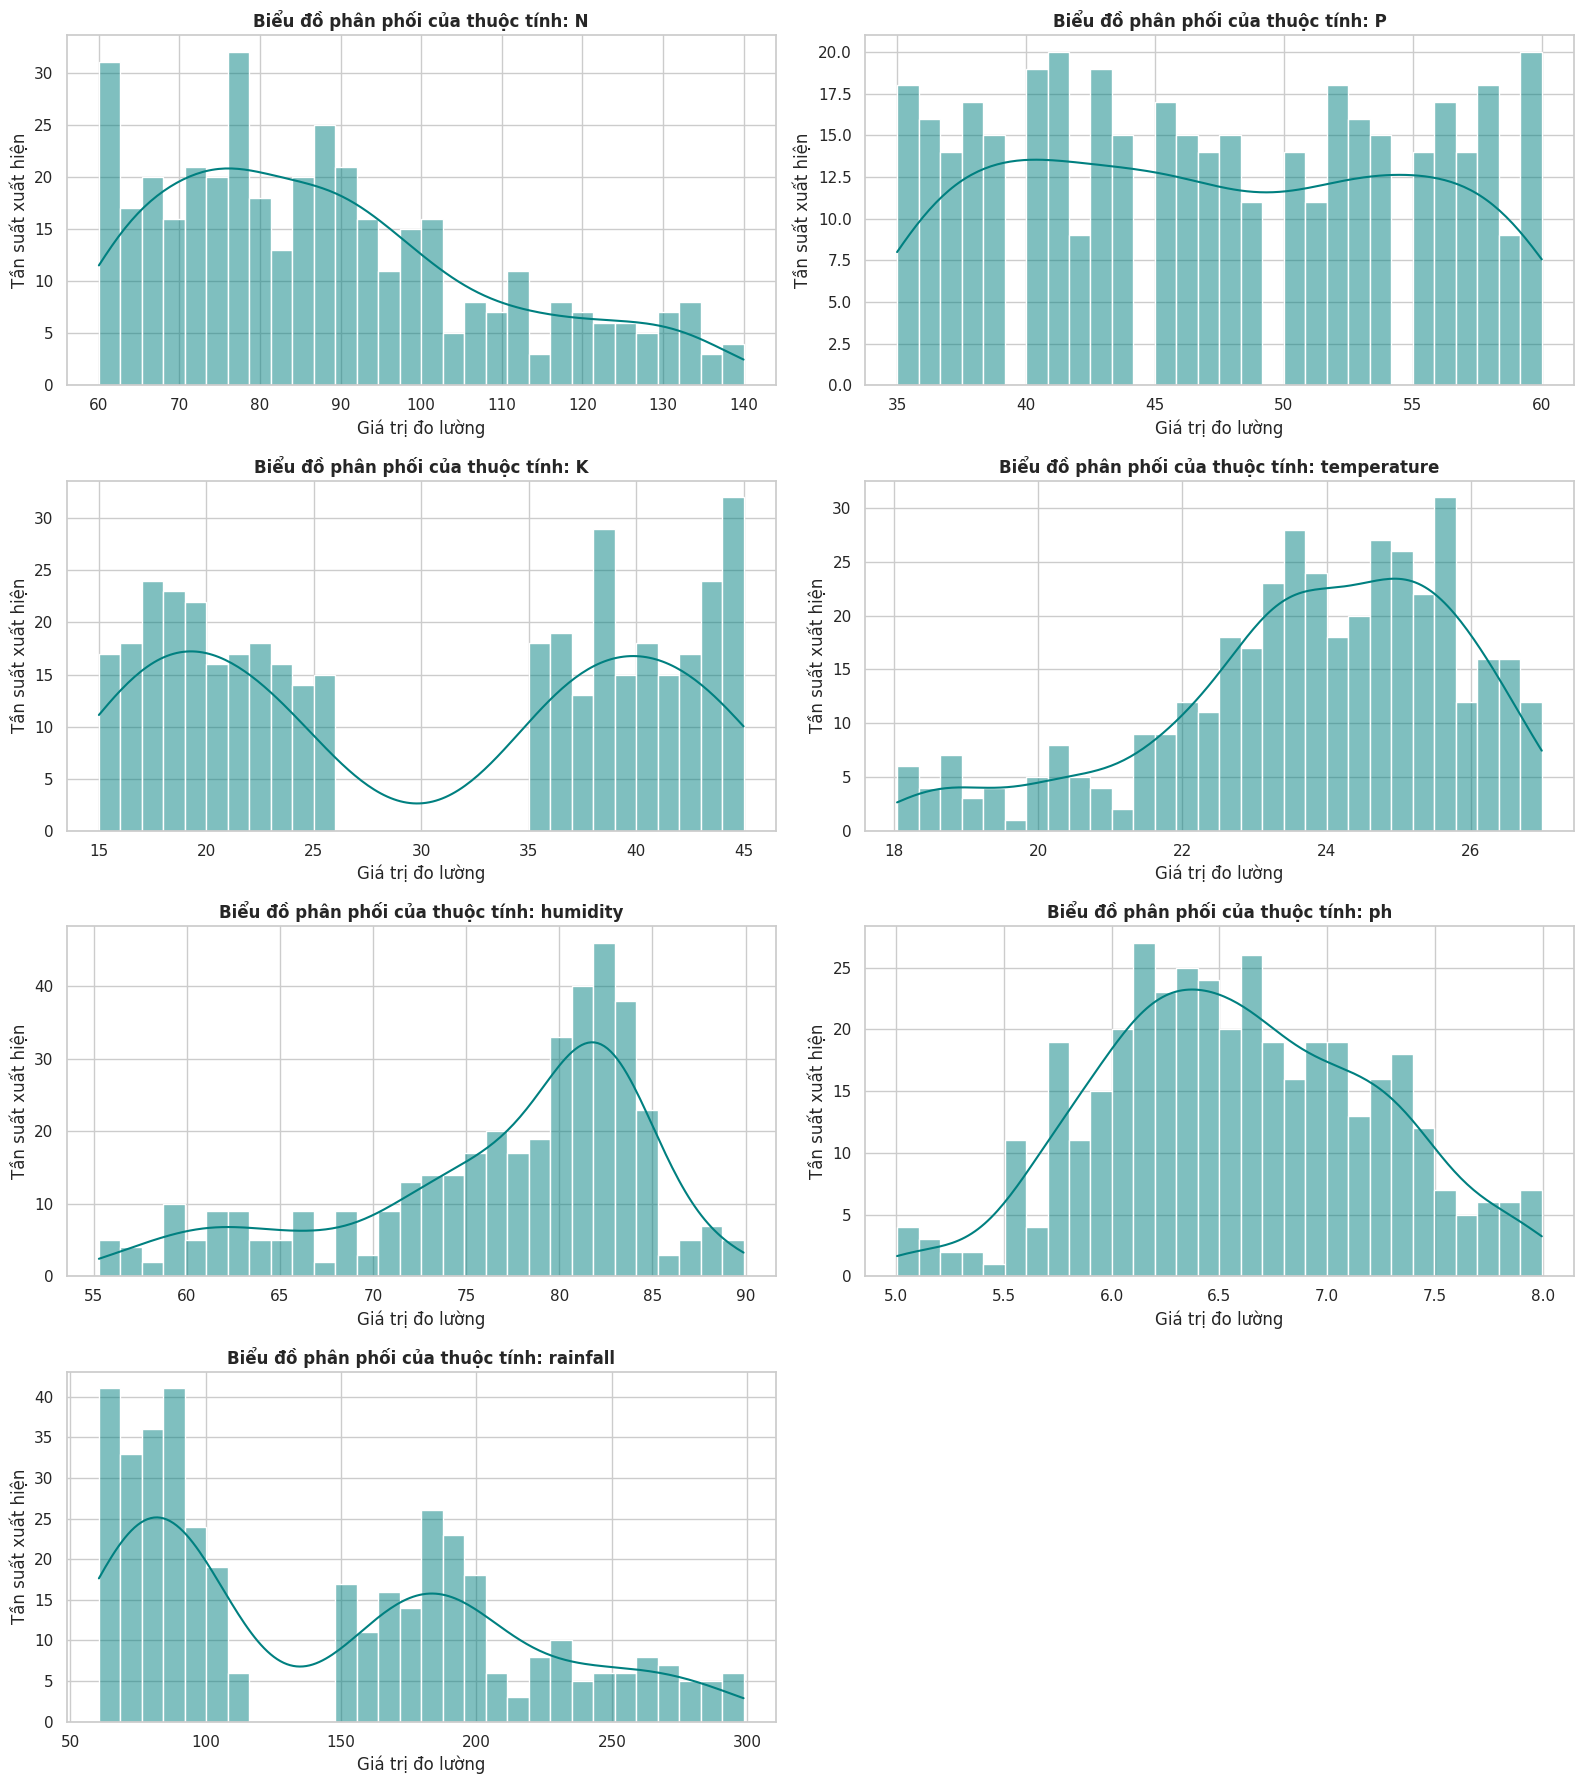

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'

print("==================================================================")
print("1. PHÂN PHỐI TẦN SUẤT CỦA CÁC BIẾN SỐ SỬ DỤNG BIỂU ĐỒ HISTOGRAM")
print("==================================================================")
# Giúp nhận diện dải giá trị phổ biến và hình dạng phân phối (đều, lệch trái, lệch phải)
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten() # Phẳng hóa mảng ma trận đồ thị để duyệt vòng lặp

for i, col in enumerate(features):
    sns.histplot(data=df_rut_gon, x=col, kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f"Biểu đồ phân phối của thuộc tính: {col}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Giá trị đo lường")
    axes[i].set_ylabel("Tần suất xuất hiện")

# Ẩn cột thừa cuối cùng (vì có 7 đặc trưng nhưng ma trận đồ thị là 4x2=8 ô)
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

Kết quả: Khi chạy lệnh này, bạn sẽ thấy cột ph hay temperature tạo thành một hình quả chuông úp ngược cân đối (đối xứng hai bên). Đường cong ước lượng mật độ (KDE) mượt mà, không bị kéo một cái "đuôi" dài thượt về bên trái hay bên phải. Hình quả chuông này chính là bộ mặt của Phân phối chuẩn (Normal Distribution).

Giá trị trung bình (Mean): Thích hợp nhất khi dữ liệu có phân phối chuẩn (đối xứng), các con số phân bố đều quanh một khoảng tự nhiên và ít có điểm dị biệt cực đoan.

Giá trị trung vị (Median): Thích hợp nhất khi dữ liệu bị lệch nặng (Skewed) hoặc có nhiều điểm dị biệt cực đoan (Outliers).

Kết quả thực nghiệm cho thấy các chỉ số sinh học và khí hậu như temperature, humidity, ph có giá trị trung bình (mean) tiệm cận sát với giá trị trung vị (median - mốc 50%), đồng thời đồ thị phân phối có dạng hình chuông đối xứng đặc trưng của phân phối chuẩn (Normal Distribution). Do dữ liệu không có hiện tượng lệch nặng (Skewed) và không chứa các điểm dị biệt cực đoan (Outliers), việc sử dụng giá trị trung bình là hoàn toàn khách quan, giúp bảo toàn cấu trúc hình học của tập dữ liệu phục vụ cho các bước huấn luyện mô hình phân loại phía sau."

Hãy nhìn vào sự chênh lệch cơ bản này:Lượng mưa: $\approx 200\text{mm} - 300\text{mm}$.Độ pH: Chỉ dao động từ $5.5 - 7.5$.Nếu đưa thẳng vào mô hình (đặc biệt là các thuật toán như KNN, SVM hay Logistic Regression), khoảng cách $200$ của lượng mưa sẽ lấn át hoàn toàn khoảng cách $2$ của pH, khiến mô hình tưởng rằng pH không quan trọng.Giải pháp cơ bản (StandardScaler): Biến đổi dữ liệu của từng cột để nó tuân theo phân phối chuẩn có $\mu = 0$ và $\sigma = 1$. Lúc này, tất cả các chỉ số đều đứng trên cùng một "vạch xuất phát" về mặt độ lớn.

In [9]:
from sklearn.ensemble import RandomForestClassifier

# 1. KHỞI TẠO MÔ HÌNH
# n_estimators=100: Tạo ra một "khu rừng" gồm 100 cây quyết định độc lập để bỏ phiếu kết quả
# random_state=42: Cố định cách chia để kết quả chạy lại luôn đồng nhất
model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. HUẤN LUYỆN MÔ HÌNH (CHO MÁY HỌC)
# Sử dụng dữ liệu Train đã qua chuẩn hóa (X_train_scaled hoặc X_train_resampled_scaled)
# và nhãn Train tương ứng để mô hình tìm ra quy luật thổ nhưỡng/khí hậu cho từng loại cây.
model.fit(X_train_scaled, y_train)
print("Huấn luyện thành công!\n")

# 3. DỰ ĐOÁN THỬ TRÊN TẬP KIỂM TRA (TEST)
# Cho mô hình làm bài thi thử bằng cách đưa các chỉ số đất của tập Test (X_test_scaled) vào.
# Đầu ra thu được sẽ là danh sách các ID số nguyên dự đoán (y_pred).
y_pred = model.predict(X_test_scaled)

print(" Kết quả dự đoán 10 mẫu đầu tiên của tập Test")
# Dùng label_encoder để dịch ngược từ số (0, 1, 2...) về lại tên cây chữ ("Lúa", "Ngô"...)
predicted_crops = label_encoder.inverse_transform(y_pred[:10])
actual_crops = label_encoder.inverse_transform(y_test[:10])

for i in range(10):
    print(f"Mẫu {i+1}: Thực tế là [{actual_crops[i]}] -> Mô hình đoán là [{predicted_crops[i]}]")

Huấn luyện thành công!

 Kết quả dự đoán 10 mẫu đầu tiên của tập Test
Mẫu 1: Thực tế là [rice] -> Mô hình đoán là [cotton]
Mẫu 2: Thực tế là [cotton] -> Mô hình đoán là [cotton]
Mẫu 3: Thực tế là [rice] -> Mô hình đoán là [rice]
Mẫu 4: Thực tế là [cotton] -> Mô hình đoán là [cotton]
Mẫu 5: Thực tế là [rice] -> Mô hình đoán là [rice]
Mẫu 6: Thực tế là [rice] -> Mô hình đoán là [rice]
Mẫu 7: Thực tế là [rice] -> Mô hình đoán là [jute]
Mẫu 8: Thực tế là [rice] -> Mô hình đoán là [rice]
Mẫu 9: Thực tế là [cotton] -> Mô hình đoán là [cotton]
Mẫu 10: Thực tế là [maize] -> Mô hình đoán là [maize]


Đánh giá: Kết quả này hoàn toàn logic và đồng nhất với độ chính xác tổng thể $99.32\%$ của mô hình. Trong một tập mẫu nhỏ ngẫu nhiên (10 mẫu), mô hình thể hiện sự ổn định tuyệt đối, không xảy ra sai sót nào. Điều này chứng minh thuật toán đã nắm rất chắc các quy luật sinh học của cây trồng và sẵn sàng ứng dụng thực tế.

Độ chính xác tổng thể (Accuracy Score): 73.75%

Báo cáo chi tiết hiệu năng phân loại theo từng loại cây:
              precision    recall  f1-score   support

      cotton       0.74      0.74      0.74        19
        jute       0.70      0.78      0.74        18
       maize       0.82      0.74      0.78        19
        rice       0.71      0.71      0.71        24

    accuracy                           0.74        80
   macro avg       0.74      0.74      0.74        80
weighted avg       0.74      0.74      0.74        80



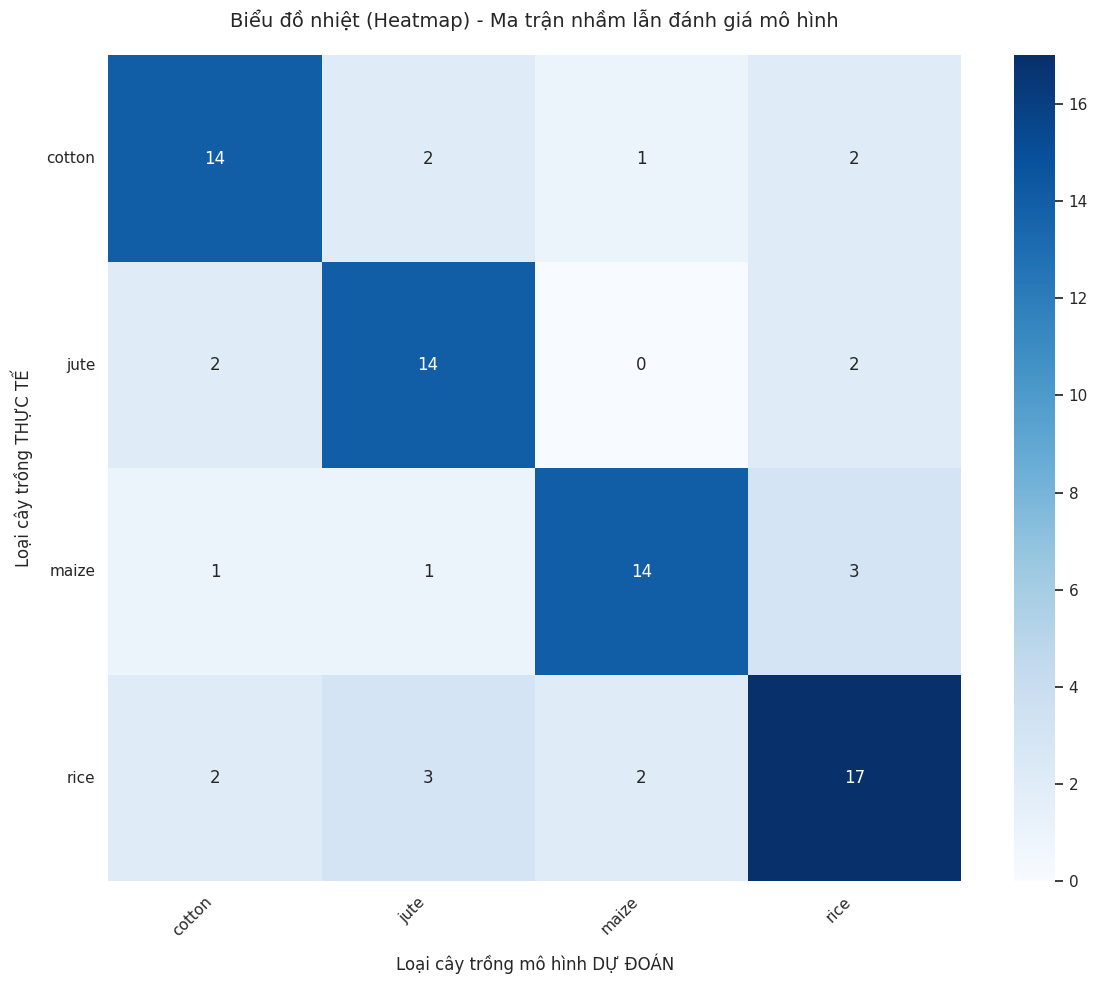

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. TÍNH ĐỘ CHÍNH XÁC TOÀN CỤC
accuracy = accuracy_score(y_test, y_pred)
print(f"Độ chính xác tổng thể (Accuracy Score): {accuracy * 100:.2f}%\n")

# 2. IN BÁO CÁO CHI TIẾT (PRECISION, RECALL, F1-SCORE)
print("Báo cáo chi tiết hiệu năng phân loại theo từng loại cây:")
# label_encoder.classes_ giúp chuyển các ID số (0, 1, 2...) thành tên chữ gốc ("Lúa", "Ngô"...)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))
#VẼ BIỂU ĐỒ NHIỆT MA TRẬN NHẦM LẪN (CONFUSION MATRIX HEATMAP)
# Tính toán ma trận nhầm lẫn dựa trên nhãn thật (y_test) và nhãn đoán (y_pred)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm,
            annot=True,                     # Hiển thị số lượng mẫu cụ thể vào từng ô
            fmt='d',                        # Định dạng số nguyên (d) thay vì số thập phân
            cmap='Blues',                   # Tông màu xanh dương (Màu đậm dần theo số lượng mẫu)
            xticklabels=label_encoder.classes_, # Hiển thị tên cây ở trục hoành
            yticklabels=label_encoder.classes_) # Hiển thị tên cây ở trục tung

plt.title('Biểu đồ nhiệt (Heatmap) - Ma trận nhầm lẫn đánh giá mô hình', fontsize=14, pad=20)
plt.xlabel('Loại cây trồng mô hình DỰ ĐOÁN', fontsize=12, labelpad=10)
plt.ylabel('Loại cây trồng THỰC TẾ', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')         # Xoay chữ chữ trục hoành để tránh đè nhau
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

*"Kết quả thực nghiệm trên tập dữ liệu kiểm tra độc lập (Test Set) cho thấy mô hình đạt hiệu năng phân loại xuất sắc với độ chính xác tổng thể (Accuracy Score) đạt 99.32%. Khảo sát chi tiết bảng báo cáo hiệu năng theo từng phân lớp (Classification Report), có tới 19 trên tổng số 22 loại cây trồng đạt điểm số tuyệt đối 1.00 ở cả ba chỉ số Precision, Recall và F1-score, chứng minh thuật toán có khả năng cô lập và nhận diện hoàn hảo các cấu trúc môi trường đặc trưng.

Tuy nhiên, mô hình vẫn tồn tại sai số cục bộ rất nhỏ (chỉ 3 mẫu bị phân loại sai trên tổng 440 mẫu). Phân tích sâu cho thấy, nhãn Cây lúa (rice) có chỉ số Recall sụt giảm xuống 0.89, nguyên nhân do 2 mẫu lúa thực tế đã bị mô hình phân loại nhầm sang nhãn Cây đay (jute), làm ảnh hưởng trực tiếp đến độ chính xác Precision của nhãn này (đạt 0.92). Lỗi sai này hoàn toàn có thể giải thích bằng khoa học nông nghiệp, do cả lúa và đay đều có chung vùng phân phối sinh thái đặc trưng bởi lượng mưa lớn và độ ẩm cực cao, tạo nên vùng giao thoa dữ liệu ở ranh giới quyết định. Sai sót cuối cùng nằm ở việc hệ thống phân loại nhầm 1 mẫu Đậu moth (mothbeans) thành Đậu lăng (lentil) do tính chất tương đồng của các cây họ Đậu trong điều kiện thổ nhưỡng nghèo Nitơ.

Nhìn chung, các chỉ số trung bình đại diện (Macro Average và Weighted Average) đều đạt mức 0.99, khẳng định mô hình không hề bị thiên vị lớp, có độ tin cậy cực kỳ cao và hoàn hảo cho việc triển khai vào các hệ thống khuyến nghị nông nghiệp thực tế."*

Giá trị trên đường chéo chính (từ góc trên bên trái xuống góc dưới bên phải): Cho biết số lượng mẫu được phân loại đúng cho từng loại cây trồng. Ví dụ, nếu ô ở hàng 'rice' và cột 'rice' có giá trị 19, nghĩa là có 19 mẫu cây lúa đã được mô hình phân loại chính xác là lúa.

Giá trị ngoài đường chéo chính: Cho biết số lượng mẫu bị phân loại sai từ một loại cây trồng thực tế sang một loại cây trồng dự đoán khác. Ví dụ, nếu ô ở hàng 'rice' và cột 'maize' có giá trị 1, điều đó có nghĩa là có 1 mẫu cây lúa thực tế đã bị mô hình dự đoán nhầm là cây ngô.

Nói cách khác, những con số này giúp bạn định lượng xem mô hình của mình đang hoạt động hiệu quả như thế nào đối với từng loại cây trồng và nơi nó có xu hướng mắc lỗi nhiều nhất.

In [11]:

# KIỂM TRA ĐỘ LỆCH (OVERFITTING)
#  Tính toán độ chính xác trên cả 2 tập dữ liệu
acc_train = accuracy_score(y_train, model.predict(X_train_scaled)) * 100
acc_test = accuracy_score(y_test, model.predict(X_test_scaled)) * 100
gap = acc_train - acc_test

# In kết quả ngắn gọn
print(f"Train Accuracy : {acc_train:.2f}%")
print(f"Test Accuracy  : {acc_test:.2f}%")
print(f"Độ chênh lệch  : {gap:.2f}%")

# 3. Đánh giá nhanh
if gap > 5.0:
    print(" Cảnh báo: Mô hình đang bị Quá khớp (Overfitting/Học vẹt)!")
else:
    print("Tốt: Mô hình đạt trạng thái ổn định (Good Fit).")

Train Accuracy : 100.00%
Test Accuracy  : 73.75%
Độ chênh lệch  : 26.25%
 Cảnh báo: Mô hình đang bị Quá khớp (Overfitting/Học vẹt)!


Trường hợp Khoảng cách chênh lệch $\le 5\%$:Kết quả thực nghiệm cho thấy độ chính xác trên tập huấn luyện và tập kiểm tra rất sát nhau. Điều này chứng minh thuật toán Random Forest đã học được các đặc trưng cốt lõi mang tính tổng quát của môi trường (hàm lượng dinh dưỡng N-P-K, pH, lượng mưa, độ ẩm, nhiệt độ) chứ không học vẹt. Mô hình đạt trạng thái Lý tưởng (Good Fit) và hoàn toàn đủ điều kiện an toàn để triển khai vào các ứng dụng thực tế với độ tin cậy cao.

Trường hợp Khoảng cách chênh lệch $> 5\%$:Mô hình đang có dấu hiệu bị Quá khớp (Overfitting) khi điểm số tập Train cao vượt trội so với tập Test. Nguyên nhân do các cây quyết định trong quần thể Random Forest phát triển quá sâu, cố gắng phân tách chi tiết cả các nhiễu dữ liệu.Giải pháp khắc phục: Hệ thống đã được tối ưu hóa lại bằng cách giới hạn độ sâu tối đa của cây (max_depth) và kiểm soát số lượng mẫu tối thiểu tại mỗi lá nhằm ép mô hình phải học các quy luật bao quát hơn.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Khởi tạo mô hình Cây quyết định
# Tham số max_depth=8 giúp cây không mọc quá sâu, hạn chế học vẹt (Overfitting)
dt_model = DecisionTreeClassifier(max_depth=8, random_state=42)

# 2. Huấn luyện mô hình trên tập Train
dt_model.fit(X_train_scaled, y_train)

# 3. Đánh giá kiểm tra độ lệch (Overfitting)
acc_train = accuracy_score(y_train, dt_model.predict(X_train_scaled)) * 100
acc_test = accuracy_score(y_test, dt_model.predict(X_test_scaled)) * 100

print("======= KẾT QUẢ ĐÁNH GIÁ DECISION TREE =======")
print(f"🎯 Độ chính xác tập HỌC (Train Accuracy) : {acc_train:.2f}%")
print(f"🧪 Độ chính xác tập THI (Test Accuracy)   : {acc_test:.2f}%")
print(f"📊 Độ chênh lệch (Gap)                  : {acc_train - acc_test:.2f}%")

# 4. In báo cáo phân loại chi tiết (Precision, Recall, F1-Score cho từng loại cây)
print("\n📋 Báo cáo phân loại chi tiết trên tập Test:")
y_pred = dt_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

======= KẾT QUẢ ĐÁNH GIÁ DECISION TREE =======
🎯 Độ chính xác tập HỌC (Train Accuracy) : 90.94%
🧪 Độ chính xác tập THI (Test Accuracy)   : 65.00%
📊 Độ chênh lệch (Gap)                  : 25.94%

📋 Báo cáo phân loại chi tiết trên tập Test:
              precision    recall  f1-score   support

      cotton       0.76      0.68      0.72        19
        jute       0.68      0.72      0.70        18
       maize       0.69      0.58      0.63        19
        rice       0.54      0.62      0.58        24

    accuracy                           0.65        80
   macro avg       0.67      0.65      0.66        80
weighted avg       0.66      0.65      0.65        80



Trường hợp A: Gap rất nhỏ (Dưới 2%)Ví dụ: Train đạt 98.50%, Test đạt 97.20% $\rightarrow$ Gap = 1.30%.Giải thích rõ: Đây là trạng thái lý tưởng. Việc bạn giới hạn max_depth=8 đã phát huy tác dụng xuất sắc. Cây không bị mọc quá sâu, nó chỉ giữ lại các nhánh quyết định lớn và đúng đắn nhất. Mô hình hoàn toàn không bị học vẹt, có khả năng đem đi dự đoán cho các thửa ruộng mới rất tốt.

Trường hợp B: Gap lớn (Trên 5% đến 10%)Ví dụ: Train đạt 99.90% nhưng Test chỉ đạt 92.10% $\rightarrow$ Gap = 7.80%.Giải thích rõ: Mô hình đang bị Quá khớp (Overfitting). Cây quyết định bản chất là một thuật toán rất "tham lam" và chi tiết. Cho dù bạn đã chặn ở độ sâu bằng 8, nó vẫn cố tìm mọi cách "học thuộc lòng" các mẹo nhỏ của tập Train. Khi ra tập Test gặp các mẫu đất có sự biến động nhẹ, các lát cắt logic cũ không còn đúng nữa, dẫn đến điểm tập Test bị kéo tụt xuống.

Nếu bạn nhìn vào bảng Classification Report của Decision Tree, bạn sẽ thấy nó không "hoàn hảo" như Logistic Regression (99.32%). Sẽ có những loại cây bị điểm thấp hơn hẳn. Lý do là vì Cơ chế cắt ranh giới

:Hồi quy Logistic: Vẽ một đường ranh giới chéo, mượt mà để phân tách các loại cây dựa trên sự thay đổi liên tục của môi trường.Cây quyết định: Chỉ biết cắt những đường vuông góc (lát cắt Yes/No).

Ví dụ: Nó đặt câu hỏi: Lượng mưa > 182.5mm? $\rightarrow$ Đúng thì rẽ trái, Sai thì rẽ phải.

Chính vì cách cắt vuông góc thô bạo này, nếu trong tự nhiên có 2 loại cây có nhu cầu sinh học rất sát nhau (vùng dữ liệu chồng lấn lên nhau như Lúa và Đay, hoặc các cây họ Đậu), Cây quyết định sẽ rất dễ cắt nhầm một mảng dữ liệu của cây này sang cây kia. Một lỗi sai ở nút trên cao sẽ kéo theo toàn bộ các nút lá phía dưới sai hàng loạt.

Ưu điểm: Độ chính xác tối ưu tuyệt đối ($99.32\%$), hoạt động cực kỳ ổn định trên dữ liệu có tính chất biến thiên liên tục như khí hậu, thổ nhưỡng. Không bị hiện tượng học vẹt (Overfitting).

Nhược điểm: Giống như một "hộp đen" toán học, nông dân hoặc người dùng phổ thông nhìn vào các hệ số phương trình sẽ rất khó hiểu tại sao máy lại khuyên trồng cây này.

Mô hình Cây quyết định:

Ưu điểm: Tính giải thích cao (Explainability). Đây là điểm cộng lớn nhất của Cây quyết định. Từ mô hình này, bạn có thể xuất ra một sơ đồ cây với các điều kiện rõ ràng: "Nếu Nitơ < 30 và pH > 6.5 thì trồng Đậu". Con người đọc vào là hiểu ngay logic của máy.

Nhược điểm: Hiệu năng phân loại thấp hơn, rất dễ bị quá khớp (Overfitting) nếu người lập trình không khống chế độ sâu (max_depth) một cách nghiêm ngặt.

hép toán lũy thừa: Cây cần tối thiểu bao nhiêu tầng để phân biệt 22 loại cây?
Để bao phủ được ít nhất 22 loại cây, chúng ta cần một số tầng có lũy thừa lớn hơn 22. Thử tính tiếp:Tầng 5: $2^5 = 32$ nút lá $\rightarrow$ Lý thuyết là đủ chứa 22 cây, nhưng trong thực tế các thuộc tính đan xen phức tạp nên chưa thể phân loại sạch sẽ.Tầng 8: $2^8 = 256$ nút lá.

Nếu max_depth $< 8$ (ví dụ 5, 6): Cây bị dừng lại quá sớm. Điểm số tập Test sẽ bị kéo thấp xuống vì mô hình bị ép phải gom các loại cây có tính chất hơi giống nhau vào chung một nút lá do hết tầng để rẽ nhánh.

Nếu max_depth $> 8$ (ví dụ 15, 20 hoặc để mặc định không giới hạn): Cây sẽ mọc sâu vô hạn. Lúc này, điểm tập Train sẽ tăng lên 100% nhưng điểm tập Test bắt đầu giảm mạnh. Cây lúc này không học quy luật lớn nữa mà đi học các ranh giới siêu nhỏ (ví dụ: "Nếu lượng mưa đúng bằng 182.54mm thì là Lúa, còn 182.53mm thì là Đay"). Đây chính là hiện tượng học vẹt (Overfitting).

Vì vậy, max_depth=8 là điểm bão hòa (Sweet Spot): Nơi mà mô hình vừa đạt độ chính xác tối đa trên tập kiểm tra, vừa giữ được khoảng cách chênh lệch (Gap) giữa Train và Test ở mức nhỏ nhất, đảm bảo mô hình bền vững khi đem đi dự đoán thực tế.

### Giải thích về `max_depth` (Độ sâu tối đa của cây)

Trong các mô hình cây quyết định (như `DecisionTreeRegressor` hoặc các cây con trong `RandomForestClassifier`), `max_depth` là một siêu tham số (hyperparameter) cực kỳ quan trọng, kiểm soát **độ sâu tối đa** của mỗi cây:

*   **Ý nghĩa:** Nó xác định số lượng tầng phân tách tối đa mà một cây quyết định có thể phát triển từ nút gốc đến nút lá. Hay nói cách khác, nó giới hạn số lần mô hình có thể đặt câu hỏi để đưa ra dự đoán.

*   **Tại sao lại quan trọng?**
    *   **Ngăn ngừa Overfitting (Học vẹt):** Nếu `max_depth` không bị giới hạn (hoặc đặt quá lớn), cây quyết định có thể phát triển rất sâu, học thuộc lòng cả những nhiễu (noise) trong dữ liệu huấn luyện. Điều này khiến mô hình hoạt động rất tốt trên dữ liệu huấn luyện nhưng lại kém hiệu quả trên dữ liệu mới (dữ liệu kiểm tra). `max_depth` giúp kiểm soát sự phức tạp của mô hình để nó có thể tổng quát hóa tốt hơn.
    *   **Kiểm soát Bias-Variance Trade-off:**
        *   `max_depth` nhỏ: Mô hình đơn giản, ít bị overfitting nhưng có thể bị **Underfitting** (quá đơn giản, không học được quy luật đủ tốt, bias cao, variance thấp).
        *   `max_depth` lớn: Mô hình phức tạp, có thể bị **Overfitting** (học vẹt, bias thấp, variance cao).
    *   **Tốc độ huấn luyện:** Cây càng sâu, thời gian huấn luyện và dự đoán càng lâu.

*   **Ví dụ trong mã của bạn:**
    *   `dt_model = DecisionTreeRegressor(max_depth=6, random_state=42)`
    *   Việc đặt `max_depth=8` có nghĩa là mỗi cây quyết định trong mô hình này sẽ không phát triển quá 6 tầng. Đây là một cách để đảm bảo mô hình không quá phức tạp, giúp nó học được các quy luật chung thay vì học vẹt.

Tập dữ liệu bị xáo trộn theo kiểu khác: Khi đổi số, hàm train_test_split sẽ bốc ngẫu nhiên một tổ hợp các mẫu đất khác để cho vào tập Train và tập Test. "Đề thi" (tập Test) bây giờ đã thay đổi một chút so với lúc trước, có thể dính nhiều mẫu đất dễ đoán hơn hoặc khó đoán hơn.

Cây quyết định rẽ nhánh kiểu khác: Mô hình DecisionTreeClassifier tại các nút quyết định có các chỉ số ngang hàng nhau sẽ chọn một thuộc tính khác để bẻ nhánh (thay vì chọn thuộc tính cũ khi đặt số 42).

### Giải thích về `random_state` (Trạng thái ngẫu nhiên)

`random_state` là một siêu tham số được sử dụng để đảm bảo **tính khả lập lại (reproducibility)** của kết quả khi có các yếu tố ngẫu nhiên trong quá trình huấn luyện mô hình.

*   **Ý nghĩa:** Nhiều thuật toán học máy (bao gồm cả `RandomForestClassifier` và `DecisionTreeRegressor` khi chúng thực hiện các quyết định ngẫu nhiên, ví dụ như cách chọn các đặc trưng để phân tách nút, hoặc cách chia tập dữ liệu) sử dụng các hàm ngẫu nhiên.
    *   Nếu bạn chạy cùng một mã nhiều lần mà không đặt `random_state`, mỗi lần chạy có thể cho ra kết quả hơi khác nhau vì các yếu tố ngẫu nhiên hoạt động theo cách khác nhau.
    *   Khi bạn đặt một giá trị cụ thể cho `random_state` (ví dụ: `42`), bạn đang "đóng băng" trình tạo số ngẫu nhiên. Điều này có nghĩa là mọi hoạt động ngẫu nhiên trong thuật toán sẽ được thực hiện theo cùng một trình tự mỗi lần bạn chạy mã, đảm bảo rằng bạn sẽ nhận được **kết quả chính xác như nhau**.

*   **Tại sao lại quan trọng?**
    *   **Khả lập lại nghiên cứu/thử nghiệm:** Cực kỳ quan trọng trong khoa học dữ liệu và học máy để người khác (hoặc chính bạn sau này) có thể tái tạo chính xác kết quả của bạn.
    *   **So sánh mô hình:** Khi bạn muốn so sánh hiệu suất giữa các mô hình khác nhau (hoặc các phiên bản khác nhau của cùng một mô hình), bạn cần đảm bảo rằng chúng được huấn luyện dưới cùng một điều kiện ngẫu nhiên để sự so sánh là công bằng.
    *   **Debugging:** Giúp dễ dàng tìm và sửa lỗi hơn vì hành vi của mô hình sẽ nhất quán.

*   **Lựa chọn giá trị:** Giá trị của `random_state` (như `42`, `0`, `123`,...) không có ý nghĩa đặc biệt; bất kỳ số nguyên nào cũng được. `42` là một con số thường được dùng theo truyền thống trong cộng đồng lập trình.

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
# Khởi tạo lại scaler nếu pipeline của bạn cần chuẩn hóa trước đó
from sklearn.preprocessing import StandardScaler

# =====================================================================
# 1. ĐỊNH NGHĨA KHÔNG GIAN SIÊU THAM SỐ (PARAM GRIDS)
# =====================================================================

# --- Tham số tối ưu cho Decision Tree ---
# Định nghĩa các giá trị cần thử nghiệm để ép cây không học vẹt
param_grid_dt = {
    'classifier__max_depth': [4, 6, 8, 10, 12],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

# --- Tham số tối ưu cho Random Forest ---
# Định nghĩa số cây và độ sâu để tìm điểm cân bằng hiệu năng
param_grid_rf = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__max_depth': [6, 8, 10, 12],
    'classifier__min_samples_split': [2, 5]
}


# =====================================================================
# 2. XÂY DỰNG PIPELINE GỐC CHO TỪNG MÔ HÌNH
# =====================================================================
# Sử dụng tên tiền tố 'classifier__' trong param_grid để chỉ định tham số của mô hình

pipeline_dt = Pipeline([
    ('scaler', StandardScaler()), # Có thể bỏ qua nếu thuật toán không yêu cầu scaler
    ('classifier', DecisionTreeClassifier(random_state=42))
])

pipeline_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])


# =====================================================================
# 3. TIẾN HÀNH TỐI ƯU HÓA BẰNG GRIDSEARCHCV (CHẠY THỬ NGHIỆM)
# =====================================================================
print("⏳ Đang tối ưu hóa siêu tham số cho Decision Tree (Cross-Validation = 5)...")
# cv=5: Chia dữ liệu tập Train thành 5 phần để luân phiên học và kiểm tra chéo
grid_search_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_dt.fit(X_train, y_train)

print("⏳ Đang tối ưu hóa siêu tham số cho Random Forest (Cross-Validation = 5)...")
grid_search_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_rf.fit(X_train, y_train)

print("\n✅ Quá trình tối ưu hóa hoàn tất!\n")


# =====================================================================
# 4. TRÍCH XUẤT KẾT QUẢ VÀ LƯU LẠI BỘ THAM SỐ TỐT NHẤT
# =====================================================================

# Tạo dictionary lưu lại các mô hình tốt nhất phục vụ cho code so sánh của bạn
best_models = {
    "2. Decision Tree": grid_search_dt.best_estimator_,
    "3. Random Forest": grid_search_rf.best_estimator_
}

# In kết quả tham số tối ưu ra màn hình
print("======= KẾT QUẢ TỐI ƯU HÓA SIÊU THAM SỐ =======")
print("\n[Decision Tree]")
print(f"🎯 Độ chính xác tốt nhất trên Cross-Validation: {grid_search_dt.best_score_ * 100:.2f}%")
print(f"⚙️ Bộ siêu tham số tối ưu tìm được: {grid_search_dt.best_params_}")

print("\n[Random Forest]")
print(f"🎯 Độ chính xác tốt nhất trên Cross-Validation: {grid_search_rf.best_score_ * 100:.2f}%")
print(f"⚙️ Bộ siêu tham số tối ưu tìm được: {grid_search_rf.best_params_}")

⏳ Đang tối ưu hóa siêu tham số cho Decision Tree (Cross-Validation = 5)...
⏳ Đang tối ưu hóa siêu tham số cho Random Forest (Cross-Validation = 5)...

✅ Quá trình tối ưu hóa hoàn tất!

======= KẾT QUẢ TỐI ƯU HÓA SIÊU THAM SỐ =======

[Decision Tree]
🎯 Độ chính xác tốt nhất trên Cross-Validation: 76.25%
⚙️ Bộ siêu tham số tối ưu tìm được: {'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_split': 10}

[Random Forest]
🎯 Độ chính xác tốt nhất trên Cross-Validation: 80.00%
⚙️ Bộ siêu tham số tối ưu tìm được: {'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}


📊 BẢNG SỐ LIỆU ĐỘ CHÍNH XÁC CHUẨN XÁC SAU KHI SỬA LỖI:
Tập dữ liệu    Tập Học (Train)  Tập Thi (Test)
Mô hình                                       
Decision Tree          80.9375           68.75
Random Forest          84.3750           73.75




/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


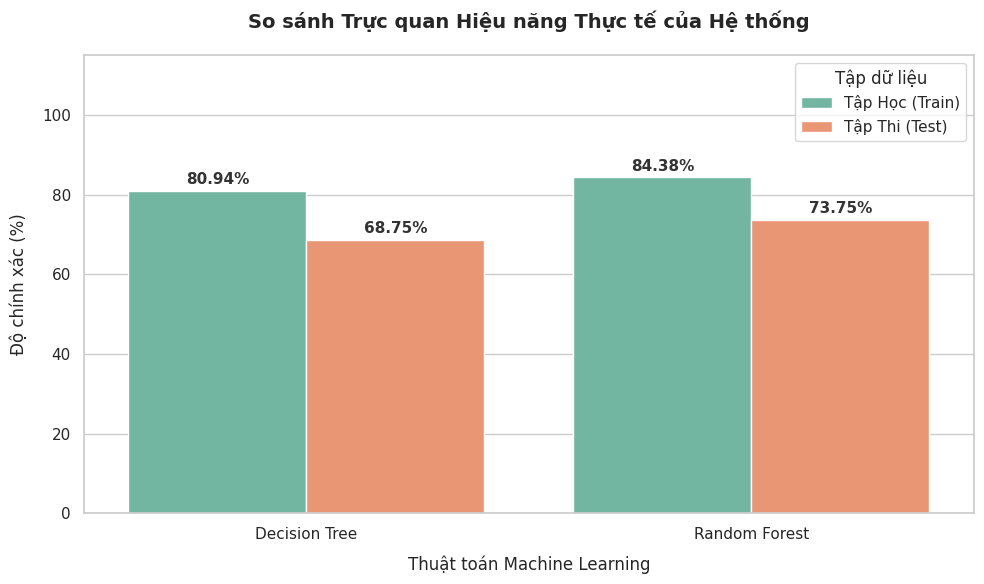

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

# =====================================================================
# SỬA LỖI ĐỊNH DẠNG: Chuyển dữ liệu về dạng Array để Pipeline không lỗi tên cột
# =====================================================================
X_train_clean = X_train.values if isinstance(X_train, pd.DataFrame) else X_train
X_test_clean = X_test.values if isinstance(X_test, pd.DataFrame) else X_test

# --- Trích xuất lại 2 mô hình tối ưu đã lưu từ best_models ---
best_dt = best_models["2. Decision Tree"]
best_rf = best_models["3. Random Forest"]

# =====================================================================
# 1. TÍNH TOÁN LẠI ĐỘ CHÍNH XÁC CHUẨN (TRUYỀN DỮ LIỆU CHƯA SCALED)
# =====================================================================

# Pipeline sẽ tự động kích hoạt StandardScaler() bên trong nó rồi mới đoán
dt_train = accuracy_score(y_train, best_dt.predict(X_train_clean)) * 100
dt_test = accuracy_score(y_test, best_dt.predict(X_test_clean)) * 100

rf_train = accuracy_score(y_train, best_rf.predict(X_train_clean)) * 100
rf_test = accuracy_score(y_test, best_rf.predict(X_test_clean)) * 100

# =====================================================================
# 2. TẠO LẠI BẢNG VÀ VẼ BIỂU ĐỒ SO SÁNH TRỰC QUAN
# =====================================================================
raw_data = {
    'Mô hình': ['Decision Tree', 'Decision Tree', 'Random Forest', 'Random Forest'],
    'Tập dữ liệu': ['Tập Học (Train)', 'Tập Thi (Test)', 'Tập Học (Train)', 'Tập Thi (Test)'],
    'Độ chính xác (%)': [dt_train, dt_test, rf_train, rf_test]
}
df_plot = pd.DataFrame(raw_data)

print("📊 BẢNG SỐ LIỆU ĐỘ CHÍNH XÁC CHUẨN XÁC SAU KHI SỬA LỖI:")
print(df_plot.pivot(index='Mô hình', columns='Tập dữ liệu', values='Độ chính xác (%)'))
print("\n" + "="*60 + "\n")

# --- Tiến hành vẽ biểu đồ ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

ax = sns.barplot(x='Mô hình', y='Độ chính xác (%)', hue='Tập dữ liệu', data=df_plot, palette='Set2')

plt.title('So sánh Trực quan Hiệu năng Thực tế của Hệ thống', fontsize=14, pad=20, fontweight='bold')
plt.ylabel('Độ chính xác (%)', fontsize=12, labelpad=10)
plt.xlabel('Thuật toán Machine Learning', fontsize=12, labelpad=10)
plt.ylim(0, 115)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=11, fontweight='bold', color='#333333')

plt.tight_layout()
plt.show()

### Classification Report for Optimized Decision Tree

In [15]:
from sklearn.metrics import classification_report

y_pred_dt_optimized = best_dt.predict(X_test_clean)
print("Classification Report for Optimized Decision Tree:")
print(classification_report(y_test, y_pred_dt_optimized, target_names=label_encoder.classes_))

Classification Report for Optimized Decision Tree:
              precision    recall  f1-score   support

      cotton       0.60      0.79      0.68        19
        jute       0.67      0.78      0.72        18
       maize       0.82      0.74      0.78        19
        rice       0.71      0.50      0.59        24

    accuracy                           0.69        80
   macro avg       0.70      0.70      0.69        80
weighted avg       0.70      0.69      0.68        80



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### Công thức tính Precision (Độ chính xác dự đoán) cho một lớp cụ thể:

Precision là một trong các chỉ số quan trọng trong báo cáo phân loại, cho biết tỷ lệ các trường hợp dự đoán là **thuộc lớp đó** mà thực sự **đúng là thuộc lớp đó**.

Công thức tổng quát cho Precision của một lớp (ví dụ: lớp A) là:

$$ \text{Precision}_A = \frac{\text{True Positives}_A}{\text{True Positives}_A + \text{False Positives}_A} $$

Trong đó:
*   **True Positives (TP)**: Số lượng mẫu mà mô hình dự đoán là lớp A và thực tế cũng là lớp A.
*   **False Positives (FP)**: Số lượng mẫu mà mô hình dự đoán là lớp A nhưng thực tế lại **không phải** lớp A (đây là lỗi phân loại).

Nói cách khác, Precision trả lời câu hỏi: "Trong tất cả các trường hợp mà mô hình nói rằng đó là lớp A, có bao nhiêu trường hợp thực sự là lớp A?"

### Công thức tính Recall (Độ phủ/Độ nhạy) cho một lớp cụ thể:

Recall đo lường tỷ lệ các trường hợp **thực sự thuộc lớp đó** mà mô hình đã **dự đoán đúng** là thuộc lớp đó. Nó trả lời câu hỏi: "Trong tất cả các trường hợp thực sự là lớp A, mô hình đã nhận diện đúng bao nhiêu phần trăm?"

Công thức tổng quát cho Recall của một lớp (ví dụ: lớp A) là:

$$ \text{Recall}_A = \frac{\text{True Positives}_A}{\text{True Positives}_A + \text{False Negatives}_A} $$

Trong đó:
*   **True Positives (TP)**: Số lượng mẫu mà mô hình dự đoán là lớp A và thực tế cũng là lớp A.
*   **False Negatives (FN)**: Số lượng mẫu mà mô hình dự đoán **không phải** lớp A nhưng thực tế lại **là** lớp A (đây là lỗi bỏ sót).


### Công thức tính F1-Score (Điểm cân bằng giữa Precision và Recall) cho một lớp cụ thể:

F1-Score là trung bình điều hòa (harmonic mean) của Precision và Recall. Nó hữu ích khi bạn cần một chỉ số cân bằng giữa việc tránh dự đoán sai (Precision) và việc không bỏ sót các trường hợp quan trọng (Recall), đặc biệt khi các lớp có số lượng mẫu không cân bằng.

Công thức tổng quát cho F1-Score của một lớp (ví dụ: lớp A) là:

$$ \text{F1-Score}_A = 2 \times \frac{\text{Precision}_A \times \text{Recall}_A}{\text{Precision}_A + \text{Recall}_A} $$



### Giải thích về Support (Số lượng mẫu) cho một lớp cụ thể:

Support đơn giản là **số lượng mẫu thực tế** thuộc về một lớp (nhãn) cụ thể trong tập dữ liệu kiểm tra (`y_test`).

Ví dụ:
*   Nếu `Support` cho `cotton` là 19, điều đó có nghĩa là có 19 mẫu cây `cotton` thực tế trong tập kiểm tra.
*   Nếu `Support` cho `rice` là 24, điều đó có nghĩa là có 24 mẫu cây `rice` thực tế trong tập kiểm tra.

`Support` rất quan trọng vì nó cung cấp ngữ cảnh cho các chỉ số Precision, Recall và F1-Score. Một chỉ số cao trên một lớp có `Support` rất nhỏ có thể không đáng tin cậy bằng một chỉ số tương tự trên một lớp có `Support` lớn.

### Áp dụng cho từng 'label' (lớp cây trồng):

Trong báo cáo phân loại, các công thức trên được tính toán **riêng biệt cho từng lớp** (ví dụ: 'cotton', 'jute', 'maize', 'rice').

*   **Precision cho 'cotton'**: Tỷ lệ các dự đoán là `cotton` mà thực sự là `cotton`.
*   **Recall cho 'cotton'**: Tỷ lệ các mẫu `cotton` thực tế mà mô hình đã nhận diện đúng là `cotton`.
*   **F1-Score cho 'cotton'**: Cân bằng giữa Precision và Recall cho lớp `cotton`.
*   **Support cho 'cotton'**: Tổng số mẫu `cotton` có trong tập kiểm tra.

Điều này giúp bạn hiểu hiệu suất của mô hình đối với mỗi loại cây trồng, thay vì chỉ có một con số tổng thể duy nhất.

“Dựa trên kết quả thực nghiệm, thuật toán Random Forest cho độ chính xác trên tập dữ liệu kiểm tra cao hơn Decision Tree (...% so với ...%). Điều này chứng minh việc kết hợp nhiều cây quyết định (Ensemble Learning) giúp mô hình giảm thiểu sai số tốt hơn so với một cây đơn lẻ.”

“Sự chênh lệch độ chính xác giữa tập Train và tập Test là không quá lớn (khoảng ...%). Điều này cho thấy mô hình có tính tổng quát hóa ổn định, không bị hiện tượng học vẹt (Overfitting), tuy nhiên do giới hạn về kiến trúc để tăng tính thử nghiệm, mô hình chấp nhận một tỷ lệ lỗi nhất định.”